# 06 · P2: quines variables fan que una avaria no es pugui reparar

Resposta: `final_vida` (1 si acaba a *End of life*, 0 si es repara o és reparable). Regressió logística amb errors agrupats per grup de reparació (apartat 5.2 del disseny):

- **M2a:** tots els registres amb descripció del problema, sense l'edat.
- **M2b:** només els que tenen edat, amb l'edat com a spline.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

import comu

dades = comu.carrega_classificats()
dades = dades[dades["problem"].notna()].copy()
for col in ("marca", "data_provider", "country"):
    dades[col] = comu.agrupa_rars(dades[col])
dades["anys_des_2020"] = dades["any_event"] - 2020
print(f"Registres: {len(dades):,}  ·  final de vida: {dades['final_vida'].sum():,} ({dades['final_vida'].mean():.1%})")

Registres: 4,427  ·  final de vida: 633 (14.3%)


In [2]:
REFS = ("C(grup_avaria, Treatment('Pantalla')) + C(marca, Treatment('Apple'))"
        " + anys_des_2020 + C(data_provider, Treatment('The Restart Project'))")

def logit(formula, df):
    return smf.glm(formula, df, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(df["group_identifier"])[0]})

def odds(model):
    t = pd.DataFrame({"OR": np.exp(model.params), "ic_inf": np.exp(model.conf_int()[0]),
                      "ic_sup": np.exp(model.conf_int()[1]), "p": model.pvalues}).drop("Intercept")
    t.index = t.index.str.replace(r"C\((\w+), Treatment\('[^']+'\)\)\[T\.(.+)\]", r"\1: \2", regex=True)
    return t

def grafic_or(t, titol):
    t = t[~t.index.str.contains("bs\\(")].sort_values("OR")
    fig, ax = plt.subplots(figsize=(6, 0.3 * len(t) + 1))
    y = np.arange(len(t))
    ax.errorbar(t["OR"], y, xerr=[t["OR"] - t["ic_inf"], t["ic_sup"] - t["OR"]],
                fmt="o", color="#2a78d6", capsize=3)
    ax.axvline(1, color="#8f8e89", lw=1)
    ax.set_xscale("log")
    ax.set_yticks(y, t.index)
    ax.set_xlabel("Odds ratio de final de vida (IC 95 %, escala log)"); ax.set_title(titol)
    plt.tight_layout(); plt.show()

## M2a: sense l'edat

Referències: pantalla, Apple i The Restart Project; l'any es compta des del 2020. No hi posem el país, perquè gairebé coincideix amb el proveïdor (per exemple, Repair Café Denmark i Dinamarca) i el model no els pot separar.

,OR,ic_inf,ic_sup,p
grup_avaria: Altres,2.719,1.853,3.992,0.000
grup_avaria: Bateria i alimentació,1.958,1.339,2.863,0.001
grup_avaria: Botons i connectors,1.506,0.927,2.444,0.098
grup_avaria: Danys interns i aigua,3.311,1.817,6.031,0.000
grup_avaria: Desconegut,1.753,1.214,2.530,0.003
grup_avaria: Port de càrrega,0.968,0.576,1.626,0.903
grup_avaria: Programari i configuració,0.943,0.599,1.486,0.801
marca: Altres,2.132,1.488,3.054,0.000
marca: Desconeguda,1.784,1.129,2.817,0.013
marca: Fairphone,1.382,0.589,3.238,0.457


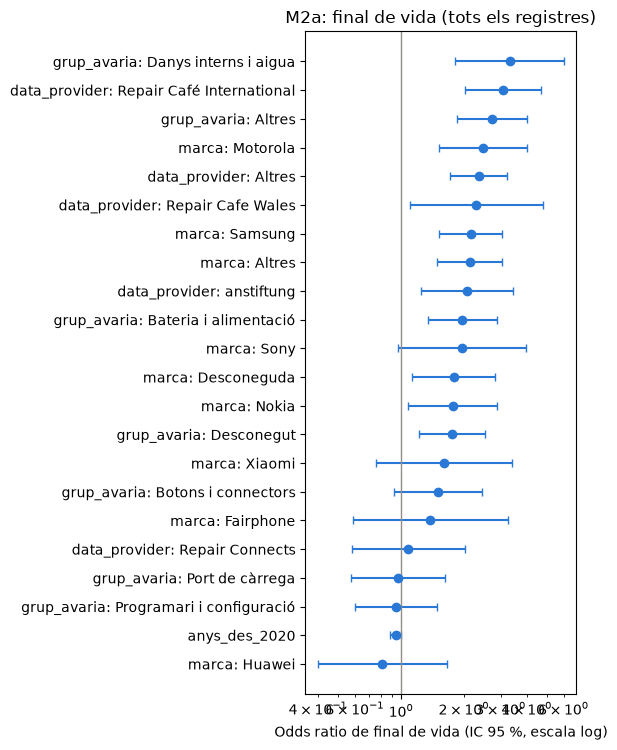

In [3]:
m2a = logit("final_vida ~ " + REFS, dades)
t2a = odds(m2a)
display(t2a.round(3))
grafic_or(t2a, "M2a: final de vida (tots els registres)")

## M2b: amb l'edat

L'edat entra amb un spline de 3 graus de llibertat. Per veure si la submostra amb edat és diferent, hi ajustem també M2a.

In [4]:
amb_edat = dades.dropna(subset=["edat_neta"]).copy()
print(f"Registres amb edat: {len(amb_edat):,}  ·  final de vida: {amb_edat['final_vida'].sum()}")
m2b = logit("final_vida ~ bs(edat_neta, df=3) + " + REFS, amb_edat)
m2a_sub = logit("final_vida ~ " + REFS, amb_edat)
comparacio = pd.DataFrame({"M2a (tots)": t2a["OR"], "M2a (amb edat)": odds(m2a_sub)["OR"],
                           "M2b": odds(m2b)["OR"]})
comparacio.round(2)

Registres amb edat: 1,546  ·  final de vida: 203


,M2a (tots),M2a (amb edat),M2b
anys_des_2020,0.94,1.00,0.97
"bs(edat_neta, df=3)[0]",NaN,NaN,2.53
"bs(edat_neta, df=3)[1]",NaN,NaN,6.37
"bs(edat_neta, df=3)[2]",NaN,NaN,3.83
data_provider: Altres,2.35,2.45,2.24
data_provider: Repair Cafe Wales,2.29,NaN,NaN
data_provider: Repair Café International,3.07,2.40,2.30
data_provider: Repair Connects,1.08,1.30,1.45
data_provider: anstiftung,2.07,0.79,0.75
grup_avaria: Altres,2.72,2.40,2.25


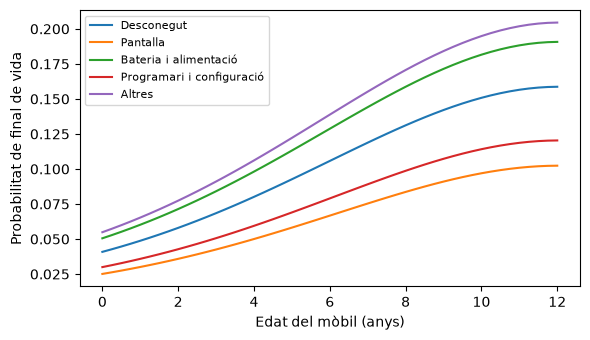

In [5]:
# Probabilitat prevista segons l'edat, per als tipus d'avaria més freqüents (resta de variables a la referència)
edats = np.linspace(0, 12, 49)
fig, ax = plt.subplots(figsize=(6, 3.5))
for grup in amb_edat["grup_avaria"].value_counts().index[:5]:
    nou = pd.DataFrame({"edat_neta": edats, "grup_avaria": grup, "marca": "Apple",
                        "anys_des_2020": 3, "data_provider": "The Restart Project"})
    ax.plot(edats, m2b.predict(nou), label=grup)
ax.set_xlabel("Edat del mòbil (anys)"); ax.set_ylabel("Probabilitat de final de vida")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Quines variables pesen més

Bosc aleatori amb les mateixes variables que M2b i importància per permutació sobre un 20 % de grups reservats. Es compara amb l'ordre dels *odds ratios* (criteri de l'apartat 5.3 del disseny).

In [6]:
VARS = ["grup_avaria", "marca", "data_provider", "anys_des_2020", "edat_neta"]
CATS = ["grup_avaria", "marca", "data_provider"]
X, y, grups = amb_edat[VARS], amb_edat["final_vida"], amb_edat["group_identifier"]
tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(X, y, grups))
bosc = make_pipeline(
    make_column_transformer((OneHotEncoder(handle_unknown="ignore"), CATS), remainder="passthrough"),
    RandomForestClassifier(500, min_samples_leaf=10, class_weight="balanced", random_state=42))
bosc.fit(X.iloc[tr], y.iloc[tr])
imp = permutation_importance(bosc, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=30, random_state=42)
pd.DataFrame({"importancia_AUC": imp.importances_mean, "sd": imp.importances_std},
             index=VARS).sort_values("importancia_AUC", ascending=False).round(3)

,importancia_AUC,sd
data_provider,0.041,0.041
edat_neta,0.039,0.020
grup_avaria,0.013,0.025
marca,-0.000,0.015
anys_des_2020,-0.008,0.011


## Validació: AUC en validació creuada agrupada per grup de reparació

In [7]:
logistica = make_pipeline(
    make_column_transformer((OneHotEncoder(handle_unknown="ignore"), CATS), remainder="passthrough"),
    LogisticRegression(max_iter=2000))
cv = GroupKFold(5)
for nom, model in [("Logística", logistica), ("Bosc aleatori", bosc)]:
    auc = cross_val_score(model, X, y, groups=grups, cv=cv, scoring="roc_auc")
    print(f"{nom}: AUC {auc.mean():.2f} ± {auc.std():.2f}")

Logística: AUC 0.64 ± 0.02


Bosc aleatori: AUC 0.65 ± 0.03


## Sensibilitat

Odds ratios del tipus d'avaria amb definicions alternatives.

In [8]:
sense_reparables = dades[dades["repair_status"] != "Repairable"]
nomes_mf = dades[dades["font_avaria"] == "MobiFix"]
sens = pd.DataFrame({
    "M2a": t2a["OR"],
    "sense reparables": odds(logit("final_vida ~ " + REFS, sense_reparables))["OR"],
    "només MobiFix": odds(logit("final_vida ~ " + REFS, nomes_mf))["OR"],
})
sens[sens.index.str.startswith("grup_avaria")].round(2)

,M2a,sense reparables,només MobiFix
grup_avaria: Altres,2.72,2.38,5.13
grup_avaria: Bateria i alimentació,1.96,2.19,2.36
grup_avaria: Botons i connectors,1.51,1.38,2.25
grup_avaria: Danys interns i aigua,3.31,3.59,5.27
grup_avaria: Desconegut,1.75,1.46,5.34
grup_avaria: Port de càrrega,0.97,0.84,0.53
grup_avaria: Programari i configuració,0.94,0.70,2.18


## Motius de final de vida per tipus d'avaria

In [9]:
eol = dades[dades["final_vida"] == 1]
pd.crosstab(eol["grup_avaria"], eol["repair_barrier_if_end_of_life"], margins=True)

repair_barrier_if_end_of_life,Lack of equipment,No way to open product,Product too worn out,Repair information not available,Spare parts not available,Spare parts too expensive,All
grup_avaria,,,,,,,
Altres,2,2,5,7,7,4,27
Bateria i alimentació,5,6,2,4,6,9,32
Botons i connectors,3,1,1,1,5,0,11
Danys interns i aigua,0,0,1,0,2,3,6
Desconegut,23,11,8,12,15,18,87
Pantalla,5,3,2,2,6,13,31
Port de càrrega,1,3,2,1,3,1,11
Programari i configuració,8,0,4,5,1,2,20
All,47,26,25,32,45,50,225
